### EDA

Goal is to explore how LFP brain activity changes during different events such as smelling different odors. Compare activity across odors, trials, behaviors, etc...

In [2]:
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt

Reading in the files for the first rat Mitt to get an idea of what data we're working with

- LFP dataset: Each rat has 23 tetrodes attached to their head that is measuring voltage signals from different parts of their brain. Each column represents one of the tetrodes and the voltage signals it collects every ms.

- Behavior dataset: Tells us at which millisecond (row) what the rat was doing such as nose poke, what odor was presented, whether odor was in sequence or not, and what position the odor was presented in.

Together we can link the behavior to the brain signal data from the LFP dataset by joining each row together since the times are the same. Both datasets span 1 experiment (1 hour of data).

In [3]:

BVR_Mitt = Path("../data/raw_data/080718_mitt/080718_mitt_bvr.npz")
LFP_Mitt = Path("../data/raw_data/080718_mitt/080718_mitt_lfp.npz")

print("---------------")
print("LFP:")
lfp = np.load(LFP_Mitt)
lfp = pd.DataFrame(lfp["data"].T, columns=lfp["keys"])
print(lfp.head())
print(lfp.columns)

print("---------------")
print("BVR:")
bvr = np.load(BVR_Mitt)
bvr = pd.DataFrame(bvr["data"].T, columns=bvr["keys"])
print(bvr.head())
print(bvr.columns)

---------------
LFP:
   T1_LFP_Raw  T2_LFP_Raw  T3_LFP_Raw  T4_LFP_Raw  T5_LFP_Raw  T6_LFP_Raw  \
0   -0.133057   -0.157471   -0.040283   -0.061035   -0.147705   -0.157471   
1   -0.162354   -0.177002   -0.081787   -0.115967   -0.177002   -0.169678   
2   -0.192871   -0.234375   -0.119629   -0.129395   -0.197754   -0.190430   
3   -0.197754   -0.255127   -0.128174   -0.114746   -0.194092   -0.192871   
4   -0.217285   -0.246582   -0.172119   -0.140381   -0.224609   -0.203857   

   T7_LFP_Raw  T8_LFP_Raw  T9_LFP_Raw  T10_LFP_Raw  ...  T14_LFP_Raw  \
0   -0.079346   -0.153809   -0.107422    -0.109863  ...     0.450439   
1   -0.120850   -0.194092   -0.144043    -0.141602  ...     0.482178   
2   -0.158691   -0.218506   -0.189209    -0.166016  ...     0.539551   
3   -0.198975   -0.264893   -0.214844    -0.158691  ...     0.593262   
4   -0.213623   -0.253906   -0.230713    -0.185547  ...     0.638428   

   T15_LFP_Raw  T16_LFP_Raw  T17_LFP_Raw  T18_LFP_Raw  T19_LFP_Raw  \
0     0.42236

Linking the data sets together

In [4]:
df = pd.concat([bvr, lfp.drop(columns="TimeBin", errors="ignore")], axis=1)

# Adding column for odor & position based on the one-hot-encoded odor columns
odor_cols = ["Odor1", "Odor2", "Odor3", "Odor4", "Odor5"]
df["Odor"] = df[odor_cols].values @ [1, 2, 3, 4, 5]
df["Odor"] = df["Odor"].map({0: "", 1: "A", 2: "B", 3: "C", 4: "D", 5: "E"})
odor_cols = ["Position1", "Position2", "Position3", "Position4", "Position5"]
df["Position"] = df[odor_cols].values @ [1, 2, 3, 4, 5]
df.head()

,TimeBin,Odor1,Odor2,Odor3,Odor4,Odor5,Position1,Position2,Position3,Position4,...,T16_LFP_Raw,T17_LFP_Raw,T18_LFP_Raw,T19_LFP_Raw,T20_LFP_Raw,T21_LFP_Raw,T22_LFP_Raw,T23_LFP_Raw,Odor,Position
0,0.010575,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.399170,0.394287,0.421143,0.120850,0.031738,0.166016,0.036621,0.372314,,0.0
1,0.011575,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.451660,0.426025,0.471191,0.090332,-0.021973,0.107422,-0.014648,0.388184,,0.0
2,0.012575,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.494385,0.489502,0.517578,0.098877,-0.047607,0.079346,-0.037842,0.450439,,0.0
3,0.013575,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.540771,0.549316,0.593262,0.117188,-0.054932,0.068359,-0.073242,0.526123,,0.0
4,0.014575,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.579834,0.584717,0.621338,0.109863,-0.062256,0.057373,-0.061035,0.543213,,0.0


Trying to see how we know when and what odor was presented to rat
- Looks like we only get data for the ms that the odor was introduced, not getting a bunch of 1's in consecutive rows to show us how long the odor was presented to the rat.
- Need to add columns so I can distinguish start and end of trials within the sequence
    - Trial starts when rat puts nose into the port and ends when rat pulls nose out of the port

In [5]:
odor_rows = df[df["Odor"] != ""]
print(odor_rows.head(10))

           TimeBin  Odor1  Odor2  Odor3  Odor4  Odor5  Position1  Position2  \
87791    87.801575    1.0    0.0    0.0    0.0    0.0        1.0        0.0   
91309    91.319575    0.0    1.0    0.0    0.0    0.0        0.0        1.0   
94331    94.341575    0.0    0.0    1.0    0.0    0.0        0.0        0.0   
109672  109.682575    0.0    0.0    0.0    1.0    0.0        0.0        0.0   
129600  129.610575    1.0    0.0    0.0    0.0    0.0        1.0        0.0   
142967  142.977575    0.0    1.0    0.0    0.0    0.0        0.0        1.0   
174141  174.151575    0.0    0.0    1.0    0.0    0.0        0.0        0.0   
187169  187.179575    0.0    0.0    0.0    1.0    0.0        0.0        0.0   
190864  190.874575    0.0    0.0    0.0    0.0    1.0        0.0        0.0   
210349  210.359575    1.0    0.0    0.0    0.0    0.0        1.0        0.0   

        Position3  Position4  ...  T16_LFP_Raw  T17_LFP_Raw  T18_LFP_Raw  \
87791         0.0        0.0  ...    -0.013428    -0.0

Assigning trial odor to the various rows. Keeping it as 0 if there is no odor/trial actively being done.

In [6]:
# Using cumsum() because nose in = +1 and nose out = -1 and 0 when it's not doing anything with the port
df["in_port"] = df["PokeEvents"].cumsum()

# Need to add trial id # for visualizations later per trial/odor
df["trial_id"] = (df["PokeEvents"] == 1).cumsum()

# Assign odor for rows within trial. Max can be used because it's just (0,1's). Set odor to nothing when nose is out of port.
df["trial_odor"] = df.groupby("trial_id")["Odor"].transform("max")
df.loc[df["in_port"] == 0, "trial_odor"] = 0

df.head()

,TimeBin,Odor1,Odor2,Odor3,Odor4,Odor5,Position1,Position2,Position3,Position4,...,T19_LFP_Raw,T20_LFP_Raw,T21_LFP_Raw,T22_LFP_Raw,T23_LFP_Raw,Odor,Position,in_port,trial_id,trial_odor
0,0.010575,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.120850,0.031738,0.166016,0.036621,0.372314,,0.0,0.0,0,0
1,0.011575,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.090332,-0.021973,0.107422,-0.014648,0.388184,,0.0,0.0,0,0
2,0.012575,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.098877,-0.047607,0.079346,-0.037842,0.450439,,0.0,0.0,0,0
3,0.013575,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.117188,-0.054932,0.068359,-0.073242,0.526123,,0.0,0.0,0,0
4,0.014575,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.109863,-0.062256,0.057373,-0.061035,0.543213,,0.0,0.0,0,0


In [7]:
# Seeing what my data frame looks like with new columns added
df[df["in_port"] == 1]

,TimeBin,Odor1,Odor2,Odor3,Odor4,Odor5,Position1,Position2,Position3,Position4,...,T19_LFP_Raw,T20_LFP_Raw,T21_LFP_Raw,T22_LFP_Raw,T23_LFP_Raw,Odor,Position,in_port,trial_id,trial_odor
87779,87.789575,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.010986,0.030518,-0.024414,0.095215,0.073242,,0.0,1.0,1,A
87780,87.790575,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.053711,0.042725,0.018311,0.104980,0.123291,,0.0,1.0,1,A
87781,87.791575,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.008545,-0.007324,-0.046387,0.037842,0.037842,,0.0,1.0,1,A
87782,87.792575,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.023193,-0.019531,-0.053711,0.018311,-0.025635,,0.0,1.0,1,A
87783,87.793575,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.012207,-0.036621,-0.054932,0.019531,-0.036621,,0.0,1.0,1,A
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5160151,7264.634575,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.013428,0.093994,0.021973,0.102539,-0.064697,,0.0,1.0,292,E
5160152,7264.635575,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.032959,0.067139,0.028076,0.080566,-0.057373,,0.0,1.0,292,E
5160153,7264.636575,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.043945,0.062256,0.004883,0.034180,-0.053711,,0.0,1.0,292,E
5160154,7264.637575,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.051270,0.047607,-0.012207,0.017090,0.012207,,0.0,1.0,292,E


Looking at Mitt's trials now to see how long they usually are and other metrics

Notes:
- Most odor trials took around the same time, with Odor E having the shortest trials (curious to see if it was short because it was out of sequence a lot and rat pulled nose out early or if rat kept getting it wrong)

In [8]:
summary = (df[df["in_port"] == 1]
           .groupby("trial_id")
           .agg(start=("TimeBin", "first"),
                end=("TimeBin", "last"),
                odor=("trial_odor", "first"),
                n_ms=("TimeBin", "size")))
summary["length_s"] = summary["n_ms"] / 1000

print("Average trial time:", round(summary["length_s"].mean(), 2), "s")
print("Median trial time: ", round(summary["length_s"].median(), 2), "s")
print(summary.groupby("odor")["length_s"].agg(["mean", "median"]).round(2))

Average trial time: 1.33 s
Median trial time:  1.4 s
      mean  median
odor              
A     1.30    1.41
B     1.40    1.40
C     1.38    1.42
D     1.35    1.40
E     1.15    1.36


Now have each trial assigned to the odor presented (only 1 odor per trial). Want to look at brain activity during specific odors now.

/var/folders/b0/9js29n7x6f582qs1zdcbc3l00000gn/T/ipykernel_5407/2008073676.py:61: RuntimeWarning: Mean of empty slice
  m = np.nanmean(X[sel], axis=0)
/Users/jwu/Library/Python/3.9/lib/python/site-packages/numpy/lib/_nanfunctions_impl.py:2035: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


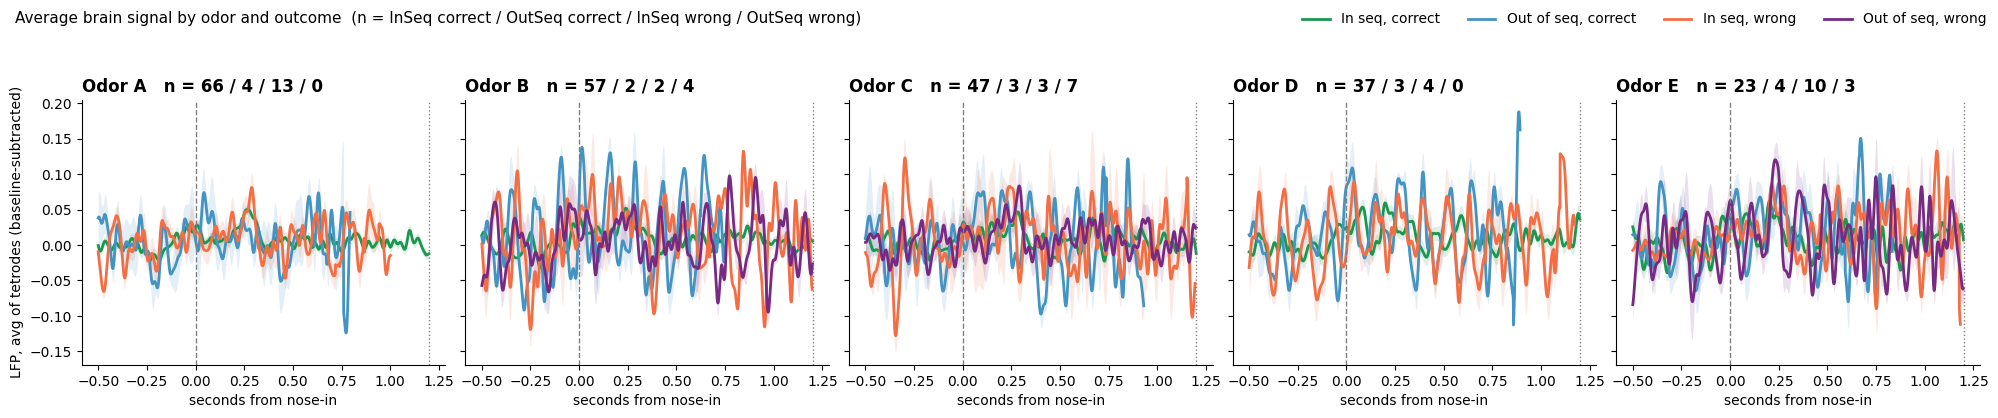

In [9]:
# Filtering signal to plot smoother. Need to add a little padding to start and end so filtering doesn't distort edge.
# Include 500 ms before nose-in (trial officially starts) and 1.2 sec after nose-in since that is
# decision threshold for rat
PRE, POST = 500, 1200
PAD = 500
ODORS = "ABCDE"
CONDS = {                              # name: (color, rule on InSeqLog, PerformanceLog)
    "In seq, correct":     ("#1a9850", lambda s, p: (s == 1)  & (p == 1)),    # green
    "Out of seq, correct": ("#4393c3", lambda s, p: (s == -1) & (p == 1)),    # blue
    "In seq, wrong":       ("#f46d43", lambda s, p: (s == 1)  & (p == -1)),   # orange: pulled nose out too early
    "Out of seq, wrong":   ("#762a83", lambda s, p: (s == -1) & (p == -1)),   # purple: kept nose in too long
}

odor_cols = ["Odor1", "Odor2", "Odor3", "Odor4", "Odor5"]
lfp_cols  = [c for c in df.columns if c.endswith("_LFP_Raw")]  # T1, T2...T23_LFP_Raw columns
odor_rows = np.flatnonzero(df[odor_cols].values.sum(axis=1) == 1)
poke_in   = df[df["PokeEvents"] == 1].index.to_numpy()
poke_out  = df[df["PokeEvents"] == -1].index.to_numpy()

start = []
end = []
for r in odor_rows:                                          # each odor delivery
    start.append(max(p for p in poke_in  if p <= r))         # latest nose-in at or before it
    end.append(  min(p for p in poke_out if p >  r))         # earliest nose-out after it

odor  = df[odor_cols].values[odor_rows].argmax(axis=1)       # 0-4 = A-E
inseq = df["InSeqLog"].values[odor_rows]
perf  = df["PerformanceLog"].values[odor_rows]

# Making sure values are numbers, not strings
L = df[lfp_cols].values.astype("float32")
# Butter is smoothing filter. Signal data is noisy, graph will be super jagged without filtering.
# https://medium.com/@lillyputr/butterworth-filter-on-a-signal-in-python-a6cb94929454
sos = butter(4, 30, btype="low", fs=1000, output="sos")

# Grab all the trial data (from PRE ms before nose-in to POST ms after nose-in + additional padding for filtering)
X = np.stack([L[s - PRE - PAD : s + POST + PAD] for s in start])
# Apply signal filter to smooth the data out. Remove padding after filter is done.
X = sosfiltfilt(sos, X, axis=1)[:, PAD:-PAD]

# Subtract the pre-trial average to get a baseline-subtracted signal.
# The tetrodes don't all start at the same level, so this equalizes their starting point.
X = X - X[:, :PRE, :].mean(axis=1, keepdims=True)
# Average across all 23 tetrodes to one data point per ms
X = X.mean(axis=2)
# Rat left the port: don't count those ms
for i, (s, e) in enumerate(zip(start, end)):
    X[i, PRE + (e - s):] = np.nan
t = np.arange(-PRE, POST) / 1000

# Plotting the line charts
fig, axes = plt.subplots(1, 5, figsize=(20, 4.2), sharey=True)
for k, ax in enumerate(axes):
    counts = []
    for name, (color, rule) in CONDS.items():
        sel = (odor == k) & rule(inseq, perf)
        n = int(sel.sum())
        counts.append(str(n))
        if n == 0:
            continue
        m = np.nanmean(X[sel], axis=0)
        ax.plot(t, m, color=color, lw=2, label=name)
        if n > 1:
            sem = np.nanstd(X[sel], axis=0) / np.sqrt(np.sum(~np.isnan(X[sel]), axis=0))
            ax.fill_between(t, m - sem, m + sem, color=color, alpha=0.15, lw=0)
    ax.axvline(0, color="gray", ls="--", lw=1)
    ax.axvline(1.2, color="gray", ls=":", lw=1)
    ax.set_title(f"Odor {ODORS[k]}   n = " + " / ".join(counts), loc="left", fontweight="bold")
    ax.set_xlabel("seconds from nose-in")
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("LFP, avg of tetrodes (baseline-subtracted)")
handles = [plt.Line2D([], [], color=c, lw=2) for c, _ in CONDS.values()]
fig.legend(handles, list(CONDS), ncol=4, frameon=False, loc="upper right")
fig.suptitle("Average brain signal by odor and outcome  "
             "(n = InSeq correct / OutSeq correct / InSeq wrong / OutSeq wrong)",
             x=0.01, ha="left", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

Observations:
- Looks like the amplitudes when the rat guessed correctly that odor was out of sequence are larger
- Correct and in sequence amplitudes look the smallest

Maybe different tetrodes behave differently per odor, visualizing that

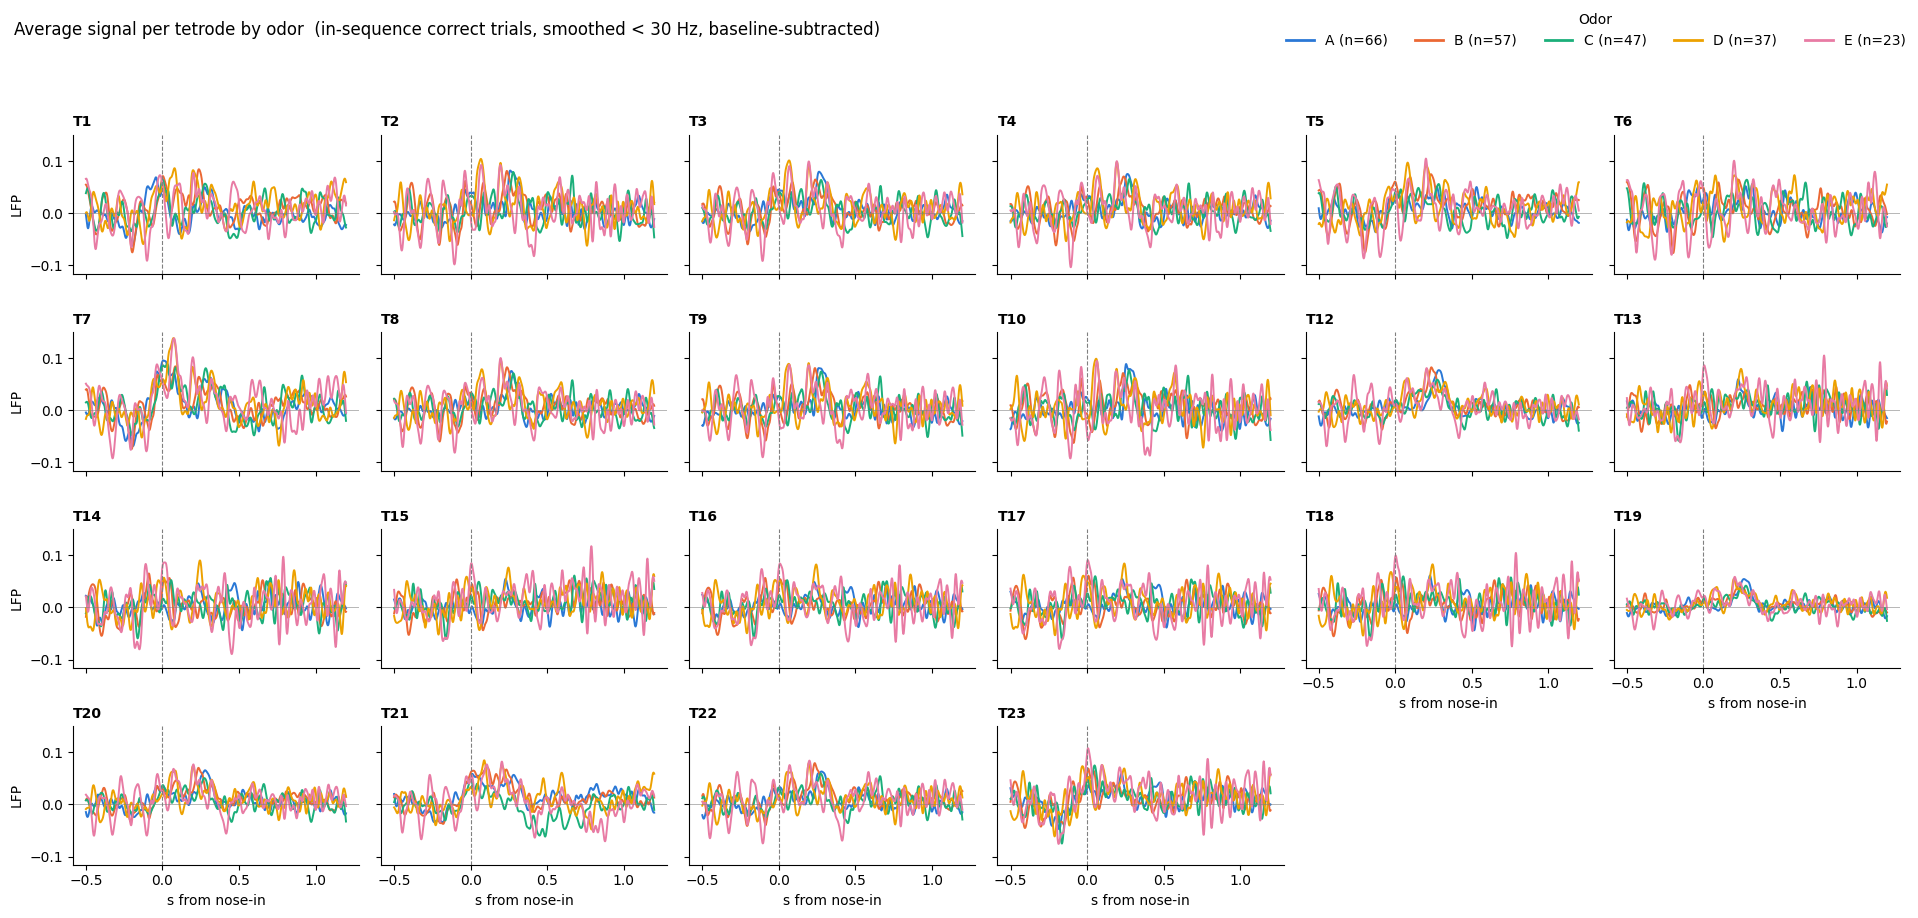

In [61]:
SHOW_ODORS = "ABCDE"        # e.g. "A" for one odor, "AE" to compare two
PRE, POST, PAD = 500, 1200, 500
ODORS  = "ABCDE"

# Convert lists to numpy arrays for boolean indexing
start = np.array(start)
end = np.array(end)

# In-sequence and correct trials only
keep = (inseq == 1) & (perf == 1)
# Stacking & filtering the LFP data
X2 = np.stack([L[s - PRE - PAD : s + POST + PAD] for s in start[keep]])
X2 = sosfiltfilt(sos, X2, axis=1)[:, PAD:-PAD]
# Subtracting average baseline per trial & tetrode
X2 = X2 - X2[:, :PRE, :].mean(axis=1, keepdims=True)                       
y2 = odor[keep]
t = np.arange(-PRE, POST) / 1000

# Plotting
n_tet = len(lfp_cols)
ncols = 6
nrows = int(np.ceil(n_tet / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 2.3 * nrows), sharex=True, sharey=True)
axes = axes.ravel()
for j, ax in enumerate(axes):
    if j >= n_tet:
        ax.axis("off"); continue
    for o in SHOW_ODORS:
        sel = y3 == ODORS.index(o)
        m = X3[sel, :, j].mean(axis=0)
        ax.plot(t, m, color=COLORS[o], lw=1.4)
        if len(SHOW_ODORS) == 1:                                   # one odor: show uncertainty band too
            sem = X3[sel, :, j].std(axis=0) / np.sqrt(sel.sum())
            ax.fill_between(t, m - sem, m + sem, color=COLORS[o], alpha=0.2, lw=0)
    ax.axvline(0, color="gray", ls="--", lw=0.8)
    ax.axhline(0, color="gray", lw=0.4)
    ax.set_title(lfp_cols[j].replace("_LFP_Raw", ""), loc="left", fontsize=10, fontweight="bold")
    ax.spines[["top", "right"]].set_visible(False)
for j in range(n_tet):
    if j + ncols >= n_tet:                     # nothing below this panel: show its x axis
        axes[j].tick_params(labelbottom=True)
        axes[j].set_xlabel("s from nose-in")
for r in range(nrows):
    axes[r * ncols].set_ylabel("LFP")

counts = {o: int((y3 == ODORS.index(o)).sum()) for o in SHOW_ODORS}
handles = [plt.Line2D([], [], color=COLORS[o], lw=2) for o in SHOW_ODORS]
fig.legend(handles, [f"{o} (n={counts[o]})" for o in SHOW_ODORS], ncol=len(SHOW_ODORS),
           frameon=False, loc="upper right", title="Odor")
fig.suptitle("Average signal per tetrode by odor  (in-sequence correct trials, smoothed < 30 Hz, baseline-subtracted)",
             x=0.01, ha="left", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

Next, wanted to visualize the raw LFP data across a given trial

66 trials of odor A available (TRIAL = 0 to 65)


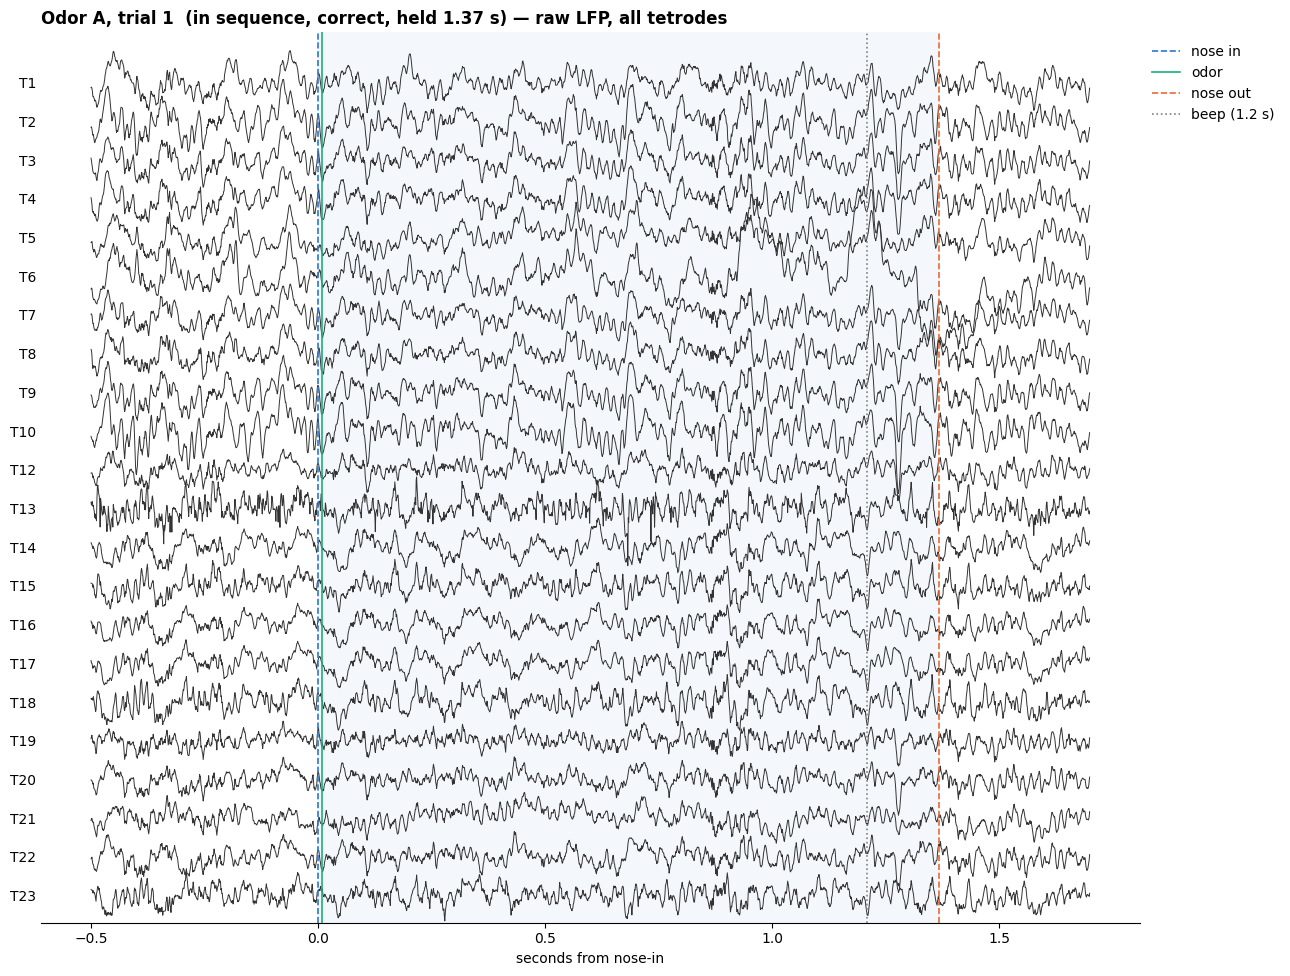

In [10]:
# Pick which trial you want to look at
ODOR  = "A"             # which odor
TRIAL = 1               # 0 = first trial of that odor, 1 = second, ...
ONLY_INSEQ_CORRECT = True
BEFORE, AFTER = 500, 1700   # ms shown around nose-in

# Get trial information based on odor and trial # selected above
ODORS = "ABCDE"
mask = odor == ODORS.index(ODOR)
# finding row indices for where odor was in sequence and rat got it correct
if ONLY_INSEQ_CORRECT:
    mask &= (inseq == 1) & (perf == 1)
idx = np.flatnonzero(mask)
print(f"{len(idx)} trials of odor {ODOR} available (TRIAL = 0 to {len(idx) - 1})")
i = idx[TRIAL]
s, e, o = start[i], end[i], odor_rows[i]

# Get the LFP data for this trial
# Center signals at mean = 0 and space out for plotting vertically
seg = L[s - BEFORE : s + AFTER, :].astype(float)
seg = seg - seg.mean(axis=0)      
gap = 4 * np.median(seg.std(axis=0)) 
t = (np.arange(-BEFORE, AFTER)) / 1000

# Plotting raw LFP signal for each tetrode for one trial
n_tet = seg.shape[1]
fig, ax = plt.subplots(figsize=(13, 0.38 * n_tet + 1.5))
for j in range(n_tet):
    ax.plot(t, seg[:, j] - j * gap, color="#333333", lw=0.7)
ax.set_yticks([-j * gap for j in range(n_tet)], [c.replace("_LFP_Raw", "") for c in lfp_cols])
ax.set_ylim(-(n_tet - 0.3) * gap, 1.3 * gap)

events = {"nose in": 0, "odor": (o - s) / 1000, "nose out": (e - s) / 1000, "beep (1.2 s)": (o - s + 1200) / 1000}
styles = {"nose in": ("#2a78d6", "--"), "odor": ("#1baf7a", "-"), "nose out": ("#eb6834", "--"), "beep (1.2 s)": ("gray", ":")}
for name, x in events.items():
    if t[0] <= x <= t[-1]:
        c, ls = styles[name]
        ax.axvline(x, color=c, ls=ls, lw=1.2, label=name)
ax.axvspan(0, (e - s) / 1000, color="#2a78d6", alpha=0.05, lw=0)   # nose in the port

result = "correct" if perf[i] == 1 else "wrong"
seq = "in sequence" if inseq[i] == 1 else "out of sequence"
ax.set_title(f"Odor {ODOR}, trial {TRIAL}  ({seq}, {result}, held {(e - s) / 1000:.2f} s) — raw LFP, all tetrodes",
             loc="left", fontweight="bold")
ax.set_xlabel("seconds from nose-in")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
fig.tight_layout()
plt.show()

Observations
- I looked through different trials and different odors, seems like tetrodes closer together have similar shape
- Maybe for latent LFP we can make a "representative tetrode" of a subgroup like T1-T4 to reduce dimensionality
- Using Odor A, Trial 1: T1-4, T5-6, T7-10, T14-T18, and T19-21 look very similar.

I noticed T13 seems messier, more frequent jagged signal than the rest.

Ex: Odor B, Trial 1
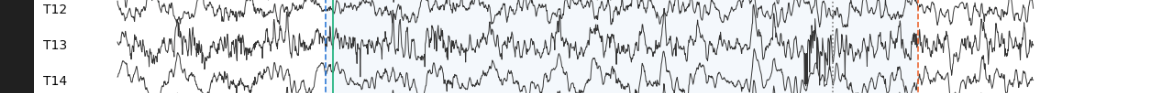

Ex: Odor D, Trial 1
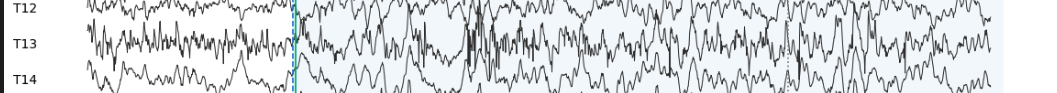

Ex: Odor A, Trial 2
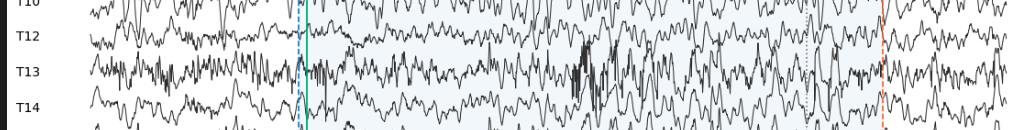

See how the rat did in different positions

In [11]:
print([c for c in df.columns if c.startswith("Position")])

['Position1', 'Position2', 'Position3', 'Position4', 'Position5', 'Position']


In [13]:
pos_cols = ["Position1", "Position2", "Position3", "Position4", "Position5"]
pos = df[pos_cols].values[odor_rows].argmax(axis=1)          # 0-4 = position 1-5
p5 = pos == 4
outcome = np.select(
    [(inseq == 1) & (perf == 1), (inseq == -1) & (perf == 1),
     (inseq == 1) & (perf == -1), (inseq == -1) & (perf == -1)],
    ["InSeq correct", "OutSeq correct", "InSeq wrong", "OutSeq wrong"],
    default="other",
)
print(pd.crosstab(pd.Series(np.array(list(ODORS))[odor[p5]], name="odor"),
                  pd.Series(outcome[p5], name="outcome"), margins=True))

outcome  InSeq correct  InSeq wrong  OutSeq correct  OutSeq wrong  All
odor                                                                  
A                    0            0               1             0    1
B                    0            0               1             2    3
C                    0            0               1             2    3
D                    0            0               1             0    1
E                   23           10               0             0   33
All                 23           10               4             4   41


Rat only got 2/3 of Odor E correct in position 5.

In [14]:
acc = pd.DataFrame({
    "position": pos + 1,
    "type": np.where(inseq == 1, "InSeq", "OutSeq"),
    "correct": perf == 1,
})
print(acc.pivot_table(index="position", columns="type", values="correct",
                      aggfunc=["mean", "count"]).round(2))

          mean        count       
type     InSeq OutSeq InSeq OutSeq
position                          
1         0.84    NaN  79.0    NaN
2         0.97   0.75  59.0    4.0
3         0.94   0.62  50.0    8.0
4         0.90   0.40  41.0   10.0
5         0.70   0.50  33.0    8.0


INTERESTING - rat accuracy is the highest in the middle. Is that by coincidence? Now plotting rolling accuracy as the trials go on.

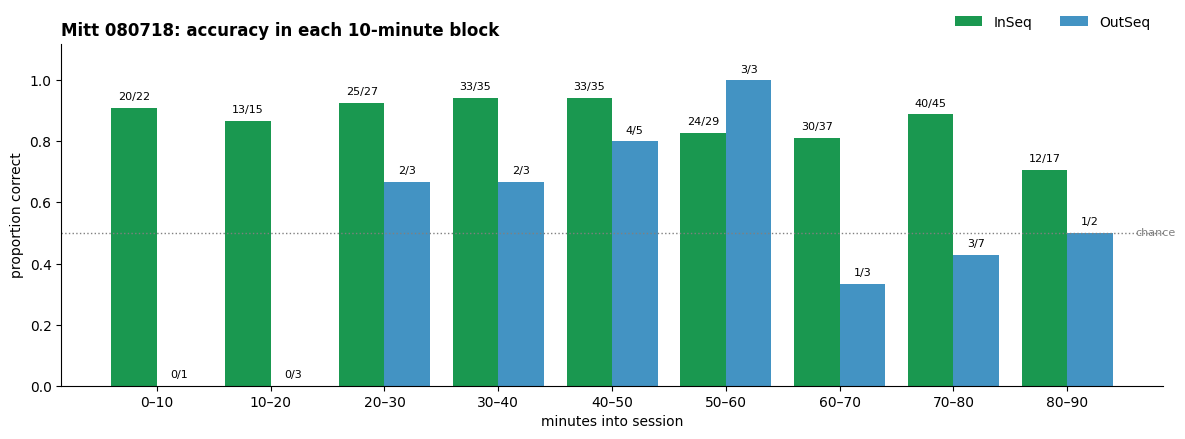

In [ ]:
# Accuracy per 10-minute block of the session, InSeq vs OutSeq
BLOCK_MIN = 10

# Break up Mitt's session data into 10min blocks to calculate accuracy per block
trials = pd.DataFrame({
    "minute":  np.array(start) / 1000 / 60,
    "type":    np.where(inseq == 1, "InSeq", "OutSeq"),
    "correct": (perf == 1),
})
trials["block"] = (trials["minute"] // BLOCK_MIN).astype(int)

summary = (trials.groupby(["block", "type"])["correct"]
                 .agg(n_correct="sum", n="count").reset_index())
summary["acc"] = summary["n_correct"] / summary["n"]

blocks = np.arange(trials["block"].max() + 1)
width = 0.4
colors = {
    "InSeq": "#1a9850", 
    "OutSeq": "#4393c3"
}

# Plotting
fig, ax = plt.subplots(figsize=(12, 4.5))
for j, typ in enumerate(["InSeq", "OutSeq"]):
    d = summary[summary["type"] == typ].set_index("block").reindex(blocks)
    x = blocks + (j - 0.5) * width
    ax.bar(x, d["acc"].fillna(0), width=width, color=colors[typ], label=typ)
    for xi, row in zip(x, d.itertuples()):
        if pd.notna(row.n):
            ax.text(xi, row.acc + 0.02, f"{int(row.n_correct)}/{int(row.n)}",
                    ha="center", va="bottom", fontsize=8)

ax.axhline(0.5, color="gray", ls=":", lw=1)
ax.text(blocks[-1] + 0.6, 0.5, "chance", color="gray", va="center", fontsize=8)
ax.set_xticks(blocks)
ax.set_xticklabels([f"{b*BLOCK_MIN}–{(b+1)*BLOCK_MIN}" for b in blocks])
ax.set_xlabel("minutes into session")
ax.set_ylabel("proportion correct")
ax.set_ylim(0, 1.12)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, ncol=2, loc="upper right", bbox_to_anchor=(1, 1.12))
ax.set_title("Mitt 080718: accuracy in each 10-minute block", loc="left", fontweight="bold")
fig.tight_layout()
plt.show()